# 02456 Deep Learning Project: PINNs: Physics-informed neural networks

The notebook contains Task 2 from the project pdf

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import torch.optim as optim
import torch.nn.init as init
from torch.nn.parameter import Parameter

# use a double precision for the gradient check.   
torch.set_default_dtype(torch.float64)
print("numpy", np.__version__, "| matplotlib", matplotlib.__version__, "| torch", torch.__version__)

numpy 2.0.2 | matplotlib 3.9.4 | torch 2.8.0


In [3]:
import numpy as np

# parameters

m, mu, k = 1.0, 5.0, 500.0 

# damping and frequencies

d   = mu / (2 * m) 
w0  = np.sqrt(k)
w   = np.sqrt(w0**2 - d**2)

# phase and amplitude

phi = np.arctan(-d / w)
A   = 1 / (2 * np.cos(phi))

def exact(t):
    return np.exp(-d * t) * (2 * A * np.cos(phi + w * t))

# data points generating

t_data = np.linspace(0, 0.5, 10)
x_data = exact(t_data)
print("t_data:", t_data)
print("x_data:", x_data)


t_data: [0.         0.05555556 0.11111111 0.16666667 0.22222222 0.27777778
 0.33333333 0.38888889 0.44444444 0.5       ]
x_data: [ 1.00000000e+00  3.79657815e-01 -5.39370953e-01 -5.97418836e-01
  6.53678406e-02  4.90074447e-01  2.32009076e-01 -2.37936847e-01
 -3.12421446e-01  7.58575452e-04]


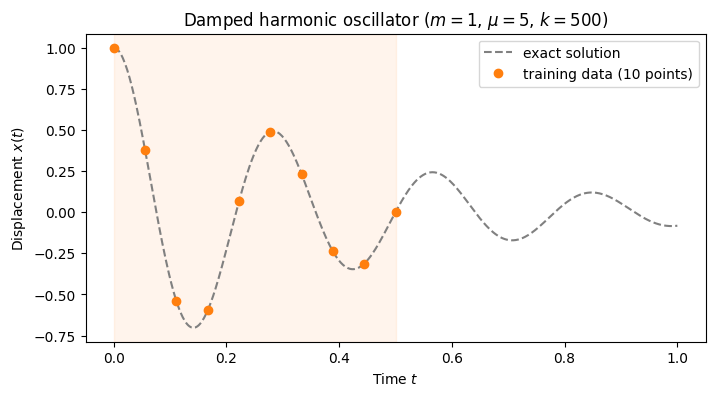

In [4]:
t_test = np.linspace(0, 1, 500)  # time range for plotting

plt.figure(figsize=(8, 4))
plt.plot(t_test, exact(t_test), color='grey', ls='--', label='exact solution')
plt.plot(t_data, x_data, 'o', color='tab:orange', label='training data (10 points)') # analytical solution and the training points
plt.axvspan(0, 0.5, color='tab:orange', alpha=0.08) # time interval used for training data
plt.xlabel('Time $t$') 
plt.ylabel('Displacement $x(t)$')
plt.title(r'Damped harmonic oscillator ($m=1$, $\mu=5$, $k=500$)')
plt.legend()
plt.show()

In [5]:
# numpy arrays to PyTorch tensors and into column vectors

t_train = torch.from_numpy(t_data).view(-1, 1)
x_train = torch.from_numpy(x_data).view(-1, 1)
t_eval = torch.from_numpy(t_test).view(-1, 1)

print("t_train", t_train.shape, "| x_train", x_train.shape, "| t_eval", t_eval.shape)

t_train torch.Size([10, 1]) | x_train torch.Size([10, 1]) | t_eval torch.Size([500, 1])


In [6]:
class Net(nn.Module):

    def __init__(self, num_hidden, w1_std=10.0):
        super(Net, self).__init__()

        # weights and biases for the hidden layer

        self.W_1 = Parameter(init.normal_(torch.empty(num_hidden, 1), 0, w1_std))
        self.b_1 = Parameter(-self.W_1.detach().view(-1) * torch.rand(num_hidden))

        #  output layer initialization

        self.W_2 = Parameter(init.xavier_normal_(torch.empty(1, num_hidden)))
        self.b_2 = Parameter(init.constant_(torch.empty(1), 0))

    def forward(self, t):
        h = torch.tanh(F.linear(t, self.W_1, self.b_1))
        return F.linear(h, self.W_2, self.b_2)

In [7]:
def train_data_only(net, num_epochs=20000, lr=1e-3, print_every=2000):
    optimizer = optim.Adam(net.parameters(), lr=lr) # optimizer and loss function
    criterion = nn.MSELoss()
    losses = []

# Train the network

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        loss = criterion(net(t_train), x_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if print_every and epoch % print_every == 0:
            print(f"Epoch {epoch:5d} : Train MSE {losses[-1]:.3e}")
    return losses

# initialize and train the network

num_hidden = 32
torch.manual_seed(0)
net = Net(num_hidden)
losses = train_data_only(net)
print(f"Final train MSE {losses[-1]:.3e}")

Epoch     0 : Train MSE 4.863e-01
Epoch  2000 : Train MSE 9.252e-04
Epoch  4000 : Train MSE 4.103e-04
Epoch  6000 : Train MSE 5.093e-05
Epoch  8000 : Train MSE 7.276e-08
Epoch 10000 : Train MSE 1.904e-12
Epoch 12000 : Train MSE 2.871e-14
Epoch 14000 : Train MSE 4.686e-07
Epoch 16000 : Train MSE 7.720e-12
Epoch 18000 : Train MSE 2.174e-13
Final train MSE 3.005e-14


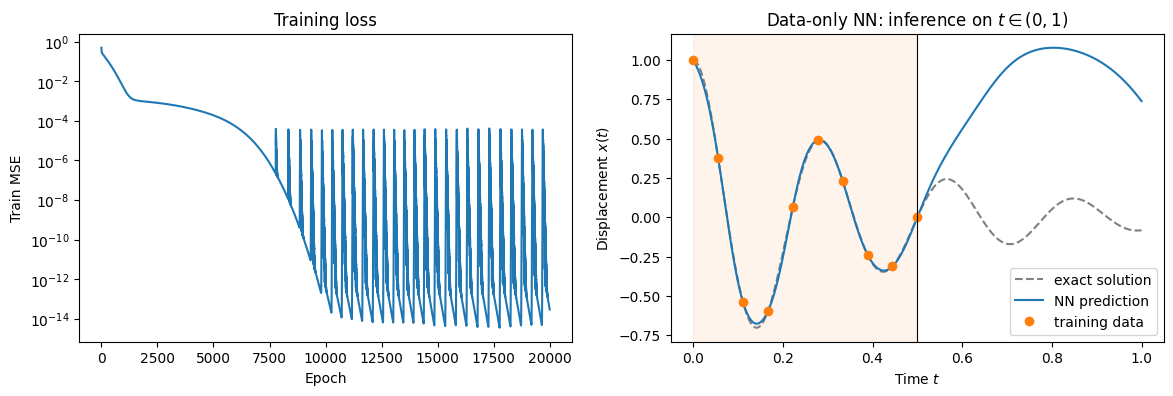

MSE vs exact solution on [0, 0.5]: 1.96e-04
MSE vs exact solution on (0.5, 1]: 7.50e-01


In [8]:
# network on the full time range

with torch.no_grad():
    x_pred = net(t_eval).numpy().ravel()
x_exact = exact(t_test)

#  training loss and the network prediction

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.semilogy(losses)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Train MSE')
ax1.set_title('Training loss')

ax2.plot(t_test, x_exact, color='grey', ls='--', label='exact solution')
ax2.plot(t_test, x_pred, color='tab:blue', label='NN prediction')
ax2.plot(t_data, x_data, 'o', color='tab:orange', label='training data')
ax2.axvspan(0, 0.5, color='tab:orange', alpha=0.08)
ax2.axvline(0.5, color='k', lw=0.8)
ax2.set_xlabel('Time $t$')
ax2.set_ylabel('Displacement $x(t)$')
ax2.set_title('Data-only NN: inference on $t \\in (0, 1)$')
ax2.legend()
plt.show()

# prediction errors inside and outside the training interval

inside, outside = t_test <= 0.5, t_test > 0.5
print(f"MSE vs exact solution on [0, 0.5]: {np.mean((x_pred[inside] - x_exact[inside])**2):.2e}")
print(f"MSE vs exact solution on (0.5, 1]: {np.mean((x_pred[outside] - x_exact[outside])**2):.2e}")

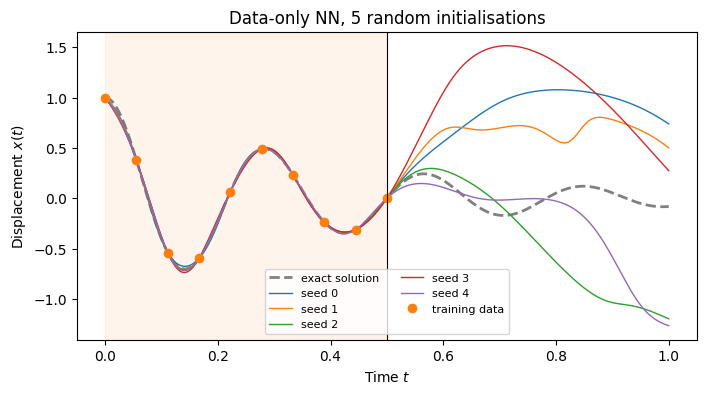

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(t_test, x_exact, color='grey', ls='--', lw=2, label='exact solution') # exact solution as a reference

# train the network with rain the network with

for seed in range(5):
    torch.manual_seed(seed)
    net_seed = Net(num_hidden)
    train_data_only(net_seed, print_every=0)
    with torch.no_grad():
        plt.plot(t_test, net_seed(t_eval).numpy().ravel(), lw=1, label=f'seed {seed}')
plt.plot(t_data, x_data, 'o', color='tab:orange', label='training data')
plt.axvspan(0, 0.5, color='tab:orange', alpha=0.08)
plt.axvline(0.5, color='k', lw=0.8)
plt.xlabel('Time $t$')
plt.ylabel('Displacement $x(t)$')
plt.title('Data-only NN, 5 random initialisations')
plt.legend(ncol=2, fontsize=8)
plt.show()